# Model comparison: cross-validation results

Compares every base model in `src/model_dispatcher.py` on the forward (time-based) validation folds
run by `src/folds.sh`: folds **21, 26, 31, 36** (`config.VALID_FOLDS`), for each position **GK, DEF, MID, FWD**.
Each fold trains on all gameweeks before it and validates on that gameweek.

The held-out test folds (`config.TEST_FOLDS`) and the ensembles from `src/ensemble.sh` are left out of the
analysis so that model choice only uses validation folds. Section 8 prints them with `src/compare.py`.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, "../src")
import compare
import config

MODELS_DIR = Path("../models")
POSITIONS = config.POSITIONS
BASELINE = "dummy"

# Plot styling: recessive grid, one accent colour, grey for everything else.
ACCENT, ACCENT_2, MUTED = "#2a78d6", "#eb6834", "#b4b2a9"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.edgecolor": "#8a8980",
        "axes.titleweight": "bold",
    }
)
pd.set_option("display.precision", 4)

## 1. Load and tag the results

In [2]:
# One results file per position, written by train.py. Keep the latest run of each model x fold.
raw = pd.concat(
    [pd.read_csv(MODELS_DIR / f"{p}_results.csv").assign(pos=p) for p in POSITIONS],
    ignore_index=True,
)
res = raw.drop_duplicates(["model", "fold", "pos"], keep="last")
res = res[res.fold.isin(config.VALID_FOLDS)].copy()
print(f"{len(raw)} result rows, {len(res)} after keeping the latest run on the validation folds")


216 result rows, 144 after keeping the latest run on the validation folds


In [3]:
# Sanity check: one row per model x fold x position.
counts = res.groupby(["model", "pos"]).size().unstack()
assert (counts == len(config.VALID_FOLDS)).all().all(), counts

# Model order: by overall mean MAE (best first). Used for every table and chart below.
MODEL_ORDER = res.groupby("model")["mae"].mean().sort_values().index.tolist()
res["pos"] = pd.Categorical(res["pos"], POSITIONS, ordered=True)
N_CELLS = res.groupby(["fold", "pos"], observed=True).ngroups
print(f"{len(res)} rows | models: {MODEL_ORDER} | folds: {sorted(res.fold.unique())} | {N_CELLS} cells")


144 rows | models: ['svr', 'cat', 'xgb', 'lgbm', 'rf', 'hgb', 'ridge', 'dt', 'dummy'] | folds: [21, 26, 31, 36] | 16 cells


## 2. Leaderboard

Mean and standard deviation of MAE and R² across all 16 fold × position cells (4 folds × 4 positions), plus the MAE improvement
over the `dummy` (mean) baseline and the average rank of each model within a cell (1 = best).

In [4]:
res["mae_rank"] = res.groupby(["fold", "pos"], observed=True)["mae"].rank()
base = res[res.model == BASELINE].set_index(["fold", "pos"])["mae"]
res["mae_vs_dummy"] = 1 - res["mae"] / res.set_index(["fold", "pos"]).index.map(base)

leader = (
    res.groupby("model")
    .agg(
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        r2_mean=("r2", "mean"),
        r2_std=("r2", "std"),
        mae_gain_vs_dummy=("mae_vs_dummy", "mean"),
        avg_rank=("mae_rank", "mean"),
        wins=("mae_rank", lambda r: int((r == 1).sum())),
    )
    .loc[MODEL_ORDER]
)
(
    leader.style.format(
        {"mae_gain_vs_dummy": "{:.1%}", "avg_rank": "{:.2f}", "wins": "{:d}"},
        precision=4,
    )
    .background_gradient(subset=["mae_mean", "avg_rank"], cmap="Blues_r")
    .background_gradient(subset=["r2_mean"], cmap="Blues")
)

,mae_mean,mae_std,r2_mean,r2_std,mae_gain_vs_dummy,avg_rank,wins
model,,,,,,,
svr,0.7848,0.2039,0.6236,0.1836,46.3%,2.69,7
cat,0.8015,0.2318,0.6165,0.1928,45.3%,3.38,1
xgb,0.8149,0.2271,0.6058,0.1950,44.6%,3.94,1
lgbm,0.8192,0.2303,0.6063,0.1833,44.3%,3.69,2
rf,0.8292,0.2263,0.6107,0.1887,43.3%,4.06,3
hgb,0.8585,0.2445,0.5735,0.2078,41.8%,5.50,2
ridge,0.8916,0.1951,0.5628,0.1949,39.0%,5.88,0
dt,0.9237,0.2109,0.5324,0.1904,36.9%,6.88,0
dummy,1.4911,0.2816,-0.0190,0.0176,0.0%,9.00,0


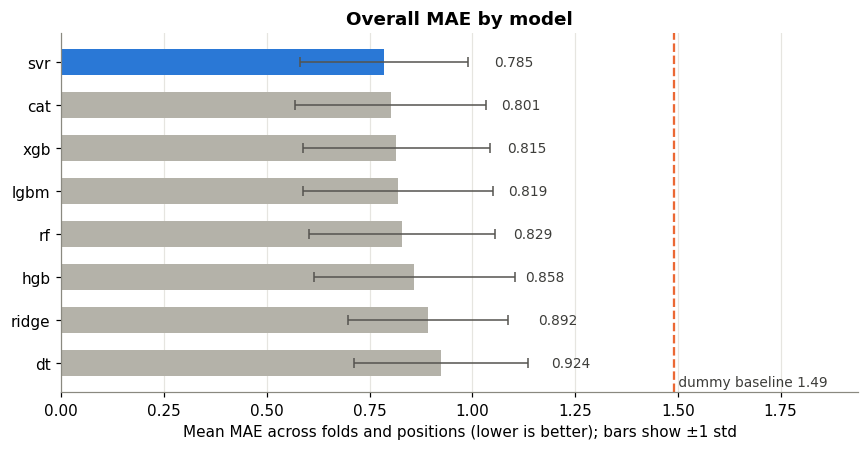

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
lb = leader.drop(BASELINE)
colors = [ACCENT if m == lb.index[0] else MUTED for m in lb.index]
ax.barh(
    lb.index,
    lb["mae_mean"],
    xerr=lb["mae_std"],
    color=colors,
    height=0.6,
    error_kw=dict(ecolor="#55544f", lw=1, capsize=3),
)
for y, (m, v) in enumerate(lb["mae_mean"].items()):
    ax.text(
        v + lb["mae_std"].max() * 1.1,
        y,
        f"{v:.3f}",
        va="center",
        fontsize=9,
        color="#3d3d3a",
    )
ax.axvline(leader.loc[BASELINE, "mae_mean"], color=ACCENT_2, ls="--", lw=1.5)
ax.text(
    leader.loc[BASELINE, "mae_mean"],
    len(lb) - 0.4,
    f" dummy baseline {leader.loc[BASELINE, 'mae_mean']:.2f}",
    color="#3d3d3a",
    fontsize=9,
    va="bottom",
)
ax.set_xlim(0, leader.loc[BASELINE, "mae_mean"] * 1.3)
ax.invert_yaxis()
ax.set_xlabel("Mean MAE across folds and positions (lower is better); bars show ±1 std")
ax.set_title("Overall MAE by model")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3. Performance by position

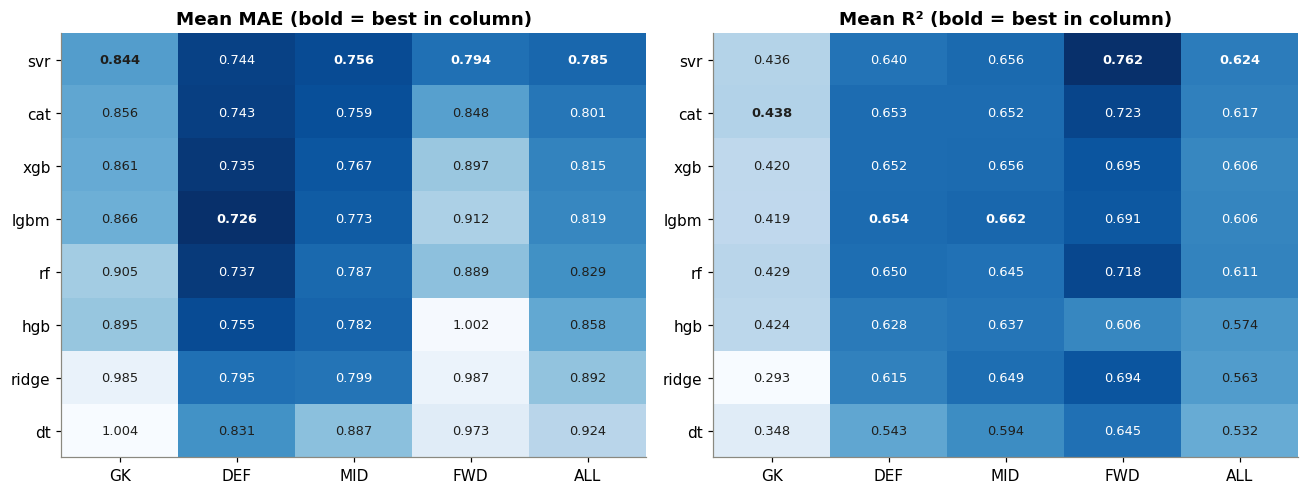

pos,GK,DEF,MID,FWD,ALL
model,,,,,
svr,0.8444,0.7443,0.7560,0.7945,0.7848
cat,0.8555,0.7430,0.7593,0.8481,0.8015
xgb,0.8610,0.7346,0.7668,0.8973,0.8149
lgbm,0.8663,0.7256,0.7727,0.9121,0.8192
rf,0.9045,0.7365,0.7871,0.8886,0.8292
hgb,0.8951,0.7550,0.7820,1.0017,0.8585
ridge,0.9851,0.7948,0.7994,0.9873,0.8916
dt,1.0044,0.8308,0.8870,0.9728,0.9237
dummy,1.2641,1.3424,1.4639,1.8939,1.4911


In [6]:
mae_pos = res.pivot_table(
    index="model", columns="pos", values="mae", aggfunc="mean", observed=True
).loc[MODEL_ORDER]
r2_pos = res.pivot_table(
    index="model", columns="pos", values="r2", aggfunc="mean", observed=True
).loc[MODEL_ORDER]
mae_pos["ALL"] = leader["mae_mean"]
r2_pos["ALL"] = leader["r2_mean"]


def heatmap(ax, df, title, cmap, fmt="{:.3f}", higher_better=False):
    data = df.values
    im = ax.imshow(data, cmap=cmap, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns)
    ax.set_yticks(range(df.shape[0]), df.index)
    ax.grid(False)
    best = df.idxmax() if higher_better else df.idxmin()
    for i, m in enumerate(df.index):
        for j, c in enumerate(df.columns):
            v = data[i, j]
            r, g, b, _ = im.cmap(im.norm(v))
            dark = (0.2126 * r + 0.7152 * g + 0.0722 * b) < 0.5  # cell luminance
            ax.text(
                j,
                i,
                fmt.format(v),
                ha="center",
                va="center",
                fontsize=8.5,
                color="white" if dark else "#1f1f1d",
                fontweight="bold" if best[c] == m else "normal",
            )
    ax.set_title(title)


no_dummy = [m for m in MODEL_ORDER if m != BASELINE]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
heatmap(axes[0], mae_pos.loc[no_dummy], "Mean MAE (bold = best in column)", "Blues_r")
heatmap(
    axes[1],
    r2_pos.loc[no_dummy],
    "Mean R² (bold = best in column)",
    "Blues",
    higher_better=True,
)
plt.tight_layout()
plt.show()
display(mae_pos)

## 4. Stability across folds

Validation sets are a single gameweek per position, so per-fold scores are noisy.
The left chart shows how each model's MAE moves across folds, averaged over positions; the three best models are coloured.
The box plot shows the spread of all 16 cells per model.

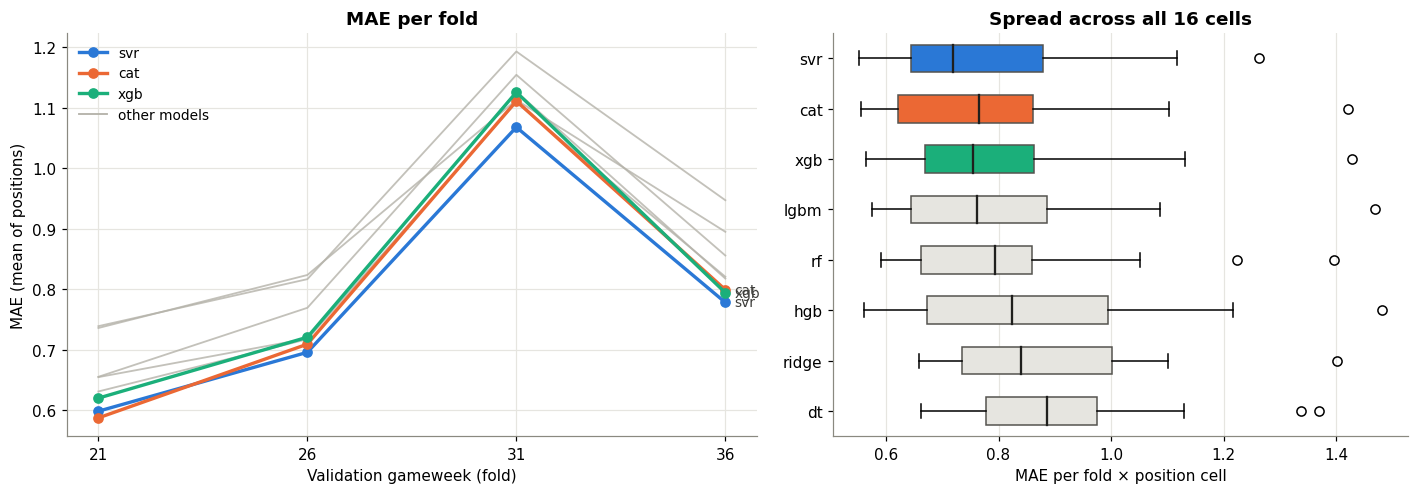

In [7]:
top3 = [m for m in MODEL_ORDER if m != BASELINE][:3]
top_colors = dict(zip(top3, [ACCENT, ACCENT_2, "#1baf7a"]))

by_fold = res.pivot_table(
    index="fold", columns="model", values="mae", aggfunc="mean", observed=True
)
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1])
)

ax = axes[0]
for m in no_dummy:
    if m in top3:
        continue
    ax.plot(by_fold.index, by_fold[m], color=MUTED, lw=1.2, alpha=0.8)
for m in top3:
    ax.plot(
        by_fold.index,
        by_fold[m],
        color=top_colors[m],
        lw=2.2,
        marker="o",
        ms=6,
        label=m,
    )
    ax.annotate(
        m,
        (by_fold.index[-1], by_fold[m].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color="#3d3d3a",
    )
ax.plot([], [], color=MUTED, lw=1.2, label="other models")
ax.set_xticks(by_fold.index)
ax.set_xlabel("Validation gameweek (fold)")
ax.set_ylabel("MAE (mean of positions)")
ax.set_title("MAE per fold")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
data = [res.loc[res.model == m, "mae"].values for m in no_dummy]
bp = ax.boxplot(
    data,
    vert=False,
    labels=no_dummy,
    patch_artist=True,
    widths=0.55,
    medianprops=dict(color="#1f1f1d", lw=1.5),
)
for patch, m in zip(bp["boxes"], no_dummy):
    patch.set_facecolor(top_colors.get(m, "#e6e5e0"))
    patch.set_edgecolor("#55544f")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE per fold × position cell")
ax.set_title(f"Spread across all {N_CELLS} cells")
plt.tight_layout()
plt.show()

In [8]:
# MAE per fold for each position: a table is easier to read than nine overlapping lines.
(
    res[res.model.isin(no_dummy)]
    .pivot_table(index=["pos", "model"], columns="fold", values="mae", observed=True)
    .reindex(pd.MultiIndex.from_product([POSITIONS, no_dummy]))
    .style.format(precision=3)
    .highlight_min(axis=None, props="font-weight:bold")
    .background_gradient(axis=None, cmap="Blues_r")
)

## 5. Is the best model significantly better?

Paired comparison of the best model against every other model on the same 16 fold × position cells.
`wins` counts cells where the best model has lower MAE. The Wilcoxon signed-rank test checks whether the
paired MAE differences are centred on zero. With 16 noisy cells, treat p-values as a guide, not a verdict.

In [9]:
best = MODEL_ORDER[0]
wide = res.pivot_table(
    index=["fold", "pos"], columns="model", values="mae", observed=True
)
rows = []
for m in MODEL_ORDER[1:]:
    d = wide[m] - wide[best]  # > 0 means `best` is better
    rows.append(
        {
            "vs": m,
            "mean_mae_diff": d.mean(),
            "best_wins": int((d > 0).sum()),
            "cells": len(d),
            "wilcoxon_p": stats.wilcoxon(d).pvalue,
        }
    )
pd.DataFrame(rows).set_index("vs").style.format(
    {"mean_mae_diff": "{:+.4f}", "wilcoxon_p": "{:.4f}"}
).set_caption(f"Best model: {best}")

,mean_mae_diff,best_wins,cells,wilcoxon_p
vs,,,,
cat,+0.0167,10,16,0.2312
xgb,+0.0301,12,16,0.0443
lgbm,+0.0344,10,16,0.1754
rf,+0.0444,10,16,0.0507
hgb,+0.0737,13,16,0.0092
ridge,+0.1068,14,16,0.0003
dt,+0.1390,16,16,0.0000
dummy,+0.7063,16,16,0.0000


## 6. Out-of-fold predictions

`train.py` saves the validation predictions of every model as `oof_{model}_{pos}_{fold}.csv`.
Set `OOF_POS` to look at another position.


In [10]:
OOF_POS = "FWD"

oof = []
for m in MODEL_ORDER:
    for f in config.VALID_FOLDS:
        oof.append(pd.read_csv(MODELS_DIR / f"oof_{m}_{OOF_POS}_{f}.csv").assign(model=m))
oof = pd.concat(oof, ignore_index=True)

oof["abs_err"] = (oof["y"] - oof["pred"]).abs()
oof_summary = (
    oof.groupby("model")
    .agg(
        mae=("abs_err", "mean"),
        bias=("pred", lambda p: (p - oof.loc[p.index, "y"]).mean()),
        r2=(
            "pred",
            lambda p: (
                1
                - ((oof.loc[p.index, "y"] - p) ** 2).sum()
                / ((oof.loc[p.index, "y"] - oof.loc[p.index, "y"].mean()) ** 2).sum()
            ),
        ),
    )
    .loc[MODEL_ORDER]
)
oof_summary  # pooled over all validation rows of OOF_POS; bias > 0 means over-prediction


,mae,bias,r2
model,,,
svr,0.8035,-0.0421,0.7496
cat,0.8602,0.0455,0.7104
xgb,0.9099,0.1146,0.6854
lgbm,0.9292,0.0790,0.6771
rf,0.9048,0.0953,0.7049
hgb,1.0192,0.0708,0.5986
ridge,0.9940,0.0661,0.6857
dt,0.9776,0.0750,0.6404
dummy,1.8819,0.0623,-0.0002


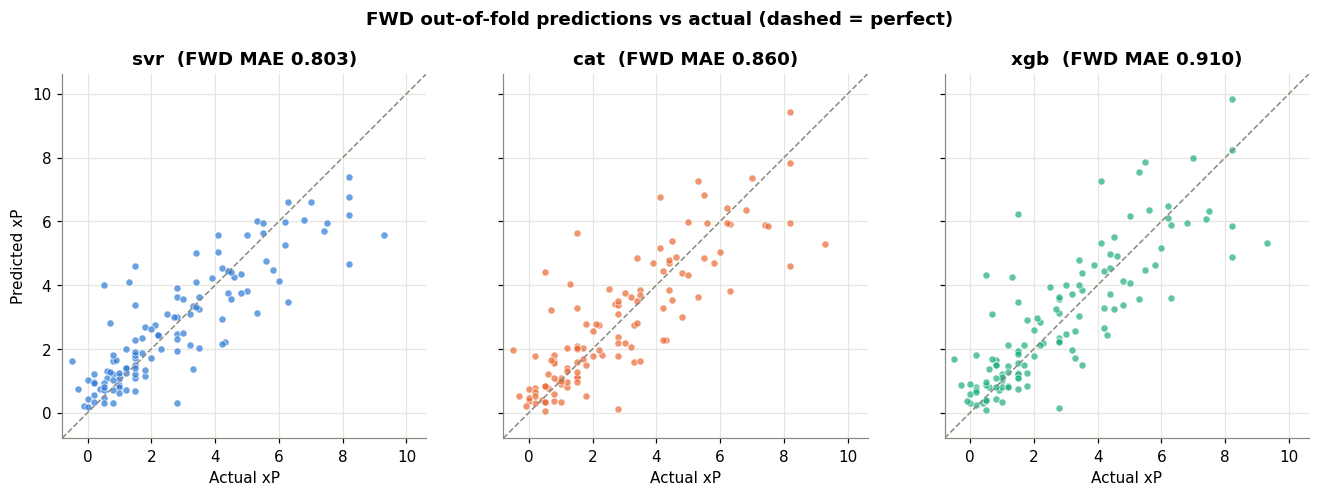

In [11]:
show = top3
fig, axes = plt.subplots(
    1, len(show), figsize=(4.2 * len(show), 4.2), sharex=True, sharey=True
)
lim = (min(oof.y.min(), oof.pred.min()) - 0.3, max(oof.y.max(), oof.pred.max()) + 0.3)
for ax, m in zip(axes, show):
    d = oof[oof.model == m]
    ax.plot(lim, lim, color="#8a8980", lw=1, ls="--")
    ax.scatter(
        d.y,
        d.pred,
        s=22,
        color=top_colors[m],
        alpha=0.7,
        edgecolor="white",
        linewidth=0.6,
    )
    ax.set_title(f"{m}  ({OOF_POS} MAE {oof_summary.loc[m, 'mae']:.3f})")
    ax.set_xlabel("Actual xP")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
axes[0].set_ylabel("Predicted xP")
plt.suptitle(
    f"{OOF_POS} out-of-fold predictions vs actual (dashed = perfect)",
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

In [12]:
# Where do the errors come from? MAE by actual-xP band for the top models (OOF_POS).
bands = pd.cut(
    oof["y"], bins=[-np.inf, 2, 4, 6, np.inf], labels=["<2", "2–4", "4–6", "6+"]
)
(
    oof[oof.model.isin(top3 + [BASELINE])]
    .assign(band=bands)
    .pivot_table(
        index="band", columns="model", values="abs_err", aggfunc="mean", observed=True
    )
    .assign(n=bands.value_counts() / oof.model.nunique())[top3 + [BASELINE, "n"]]
)

model,svr,cat,xgb,dummy,n
band,,,,,
<2,0.6562,0.6813,0.7098,1.9271,59.0
2–4,0.6701,0.8105,0.8394,0.4151,26.0
4–6,0.9079,1.0474,1.1852,1.9414,23.0
6+,1.5537,1.4401,1.4721,4.5050,13.0


## 7. Summary

The cell below prints the headline numbers. Validation sets are one gameweek per position (about 20 GK rows,
up to a few hundred MID rows), so rankings between close models can flip from fold to fold.
Prefer the average rank and the paired test over a single fold.


In [13]:
print(
    f"Best overall (mean MAE): {best}  MAE={leader.loc[best, 'mae_mean']:.4f}  R²={leader.loc[best, 'r2_mean']:.4f}"
)
print(
    f"Best by average rank:    {leader['avg_rank'].idxmin()}  (avg rank {leader['avg_rank'].min():.2f})"
)
print("Best per position (mean MAE):")
for p in POSITIONS:
    col = mae_pos[p].drop(BASELINE)
    print(
        f"  {p:>3}: {col.idxmin():<6} MAE={col.min():.4f}   runner-up {col.nsmallest(2).index[1]} ({col.nsmallest(2).iloc[1]:.4f})"
    )

Best overall (mean MAE): svr  MAE=0.7848  R²=0.6236
Best by average rank:    svr  (avg rank 2.69)
Best per position (mean MAE):
   GK: svr    MAE=0.8444   runner-up cat (0.8555)
  DEF: lgbm   MAE=0.7256   runner-up xgb (0.7346)
  MID: svr    MAE=0.7560   runner-up cat (0.7593)
  FWD: svr    MAE=0.7945   runner-up cat (0.8481)


## 8. Ensembles and held-out test folds

Same tables as `python src/compare.py`: every base model and ensemble per position, with the mean over the
validation folds and over the test folds. Choose on `valid_mae`; `test_mae` is the honest estimate.
`ens_mean_top3` picks its models from the validation ranking, so its validation score is slightly optimistic.


In [14]:
all_results = compare.load_results()
for p in POSITIONS:
    compare.print_table(compare.summarize(all_results, p), p)



=== GK === validation folds [21, 26, 31, 36], test folds [37, 38]
                                            kind  valid_mae  valid_r2  test_mae  test_r2
ens_mean_top3 [svr cat xgb]             ensemble      0.824     0.451     0.768    0.610
ens_mean_base [ridge hgb lgbm xgb svr]  ensemble      0.833     0.453     0.797    0.568
svr                                         base      0.844     0.436     0.800    0.630
cat                                         base      0.856     0.438     0.808    0.566
xgb                                         base      0.861     0.420     0.824    0.556
lgbm                                        base      0.866     0.419     0.911    0.450
hgb                                         base      0.895     0.424     0.977    0.321
rf                                          base      0.905     0.429     0.817    0.564
ridge                                       base      0.985     0.293     0.860    0.570
dt                                         